# Entraînement d'un modèle et évaluation 

Nous allons comparer le  Random Forest, K-Means, régression logistique et réseaux de neurones à partir des 13 préférences musicales. 

Puis apres on regroupe les régions en 7 groupes géographiques 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
    silhouette_score, adjusted_rand_score, normalized_mutual_info_score
)

## Charger les deux fichiers

- Le premier contient les régions d’origine.
- Le deuxième contient les régions regroupées.

In [ ]:
df = pd.read_csv("../Dataset/dataset_musique_region.csv")
df_group = pd.read_csv("../Dataset/dataset_musique_region_transforme.csv")

print("Sans regroupement :", df.shape)
print("Avec regroupement :", df_group.shape)

Sans regroupement : (1986, 14)
Avec regroupement : (1986, 16)


## Séparer les données

On choisit une seule fois les personnes pour l'entraînement et le test. Tous les modèles utilisent ensuite cette même séparation.

In [3]:
# Les deux fichiers doivent contenir les mêmes personnes, dans le même ordre.
if len(df) != len(df_group):
    raise ValueError("Les deux fichiers n'ont pas le même nombre de lignes.")

X = df.drop(columns=["region"])
y = df["region"]

if not X.reset_index(drop=True).equals(df_group[X.columns].reset_index(drop=True)):
    raise ValueError("Les personnes ne sont pas dans le même ordre dans les deux fichiers.")

# On sépare les indices une seule fois pour tous les modèles.
indices_train, indices_test = train_test_split(
    np.arange(len(df)), test_size=0.2, random_state=42
)

X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]

print("Entraînement :", len(X_train))
print("Test :", len(X_test))

Entraînement : 1588
Test : 398


## 1. Sans regroupement : 12 régions

On entraîne le Random Forest pour prédire la région d’origine.

In [4]:
modele = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42
)

modele.fit(X_train, y_train)
predictions = modele.predict(X_test)

accuracy_12 = accuracy_score(y_test, predictions)
f1_12 = f1_score(y_test, predictions, average="macro", zero_division=0)

print("Accuracy entraînement :", round(modele.score(X_train, y_train) * 100, 1), "%")
print("Accuracy test :", round(accuracy_12 * 100, 1), "%")
print("F1 macro :", round(f1_12, 3))

print(classification_report(y_test, predictions, zero_division=0))

Accuracy entraînement : 31.9 %
Accuracy test : 19.1 %
F1 macro : 0.051
                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.10      0.11      0.11        35
   Bourgogne-Franche-Comté       0.00      0.00      0.00        18
                  Bretagne       0.00      0.00      0.00        21
       Centre-Val de Loire       0.00      0.00      0.00        19
                 Grand Est       0.11      0.02      0.04        42
           Hauts-de-France       0.50      0.07      0.12        43
                 Normandie       0.00      0.00      0.00        19
        Nouvelle-Aquitaine       0.00      0.00      0.00        35
                 Occitanie       0.00      0.00      0.00        35
          Pays de la Loire       0.00      0.00      0.00        23
Provence-Alpes-Côte d'Azur       0.00      0.00      0.00        23
             Île-de-France       0.22      0.80      0.34        85

                  accuracy                 

### Matrice de confusion : 12 régions

La diagonale montre les bonnes prédictions.

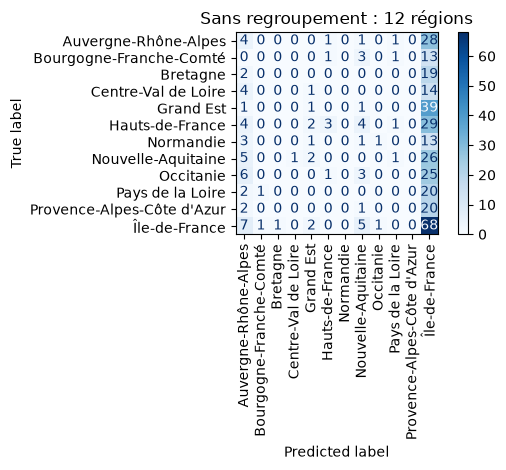

In [5]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=90, cmap="Blues")
plt.title("Sans regroupement : 12 régions")
plt.tight_layout()
plt.show()

## 2. Avec regroupement : 7 groupes

On entraîne un nouveau Random Forest avec les mêmes paramètres et les mêmes personnes que pour les 12 régions.

In [6]:
X_group = df_group[X.columns]
y_group = df_group["region_group"]

# On reprend exactement les mêmes indices que pour les 12 régions.
X_train_g, X_test_g = X_group.iloc[indices_train], X_group.iloc[indices_test]
y_train_g, y_test_g = y_group.iloc[indices_train], y_group.iloc[indices_test]

In [7]:
modele_group = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42
)

modele_group.fit(X_train_g, y_train_g)
predictions_g = modele_group.predict(X_test_g)

accuracy_7 = accuracy_score(y_test_g, predictions_g)
f1_7 = f1_score(y_test_g, predictions_g, average="macro", zero_division=0)

print("Accuracy entraînement :", round(modele_group.score(X_train_g, y_train_g) * 100, 1), "%")
print("Accuracy test :", round(accuracy_7 * 100, 1), "%")
print("F1 macro :", round(f1_7, 3))

print(classification_report(y_test_g, predictions_g, zero_division=0))

Accuracy entraînement : 38.0 %
Accuracy test : 24.9 %
F1 macro : 0.148
                      precision    recall  f1-score   support

Auvergne-Rhône-Alpes       0.11      0.06      0.08        35
              CENTRE       0.21      0.10      0.13        60
           Grand Est       0.00      0.00      0.00        42
          NORD-OUEST       0.27      0.43      0.33        83
  Nouvelle-Aquitaine       0.00      0.00      0.00        35
                 SUD       0.29      0.09      0.13        58
       Île-de-France       0.26      0.59      0.36        85

            accuracy                           0.25       398
           macro avg       0.16      0.18      0.15       398
        weighted avg       0.20      0.25      0.19       398



### Matrice de confusion : 7 groupes

La diagonale montre les bonnes prédictions.

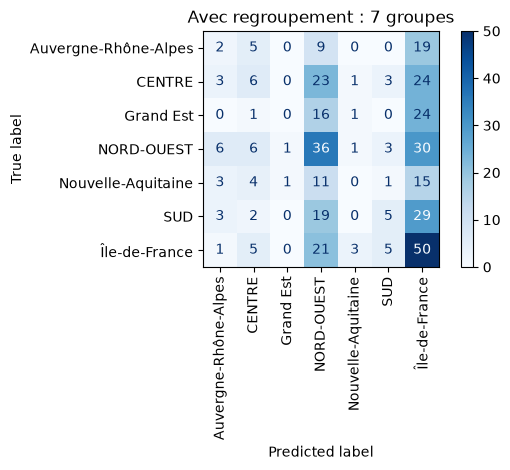

In [8]:
ConfusionMatrixDisplay.from_predictions(y_test_g, predictions_g, xticks_rotation=90, cmap="Blues")
plt.title("Avec regroupement : 7 groupes")
plt.tight_layout()
plt.show()

## 3. Comparer les résultats

- **Accuracy** : part des bonnes prédictions.
- **F1 macro** : score qui donne la même importance à chaque région (+ il est proche de 1, meilleures sont les perf)

In [9]:
comparaison = pd.DataFrame({
    "Modèle": ["12 régions", "7 groupes"],
    "Accuracy (%)": [round(accuracy_12 * 100, 1), round(accuracy_7 * 100, 1)],
    "F1 macro": [round(f1_12, 3), round(f1_7, 3)]
})
comparaison

,Modèle,Accuracy (%),F1 macro
0,12 régions,19.1,0.051
1,7 groupes,24.9,0.148


## 4. K-Means : trouver des groupes musicaux

On regroupe les personnes selon leurs goûts musicaux. On commence par choisir le nombre de groupes.

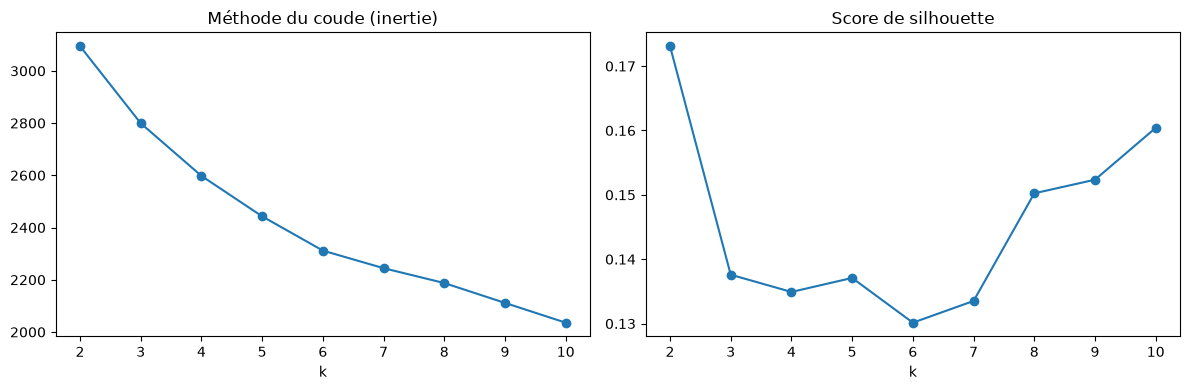

In [10]:
RANDOM_STATE = 42
valeurs_k = range(2, 11)
inerties, silhouettes = [], []

for k in valeurs_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    etiquettes = km.fit_predict(X_train)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train, etiquettes))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valeurs_k), inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("k")
axes[1].plot(list(valeurs_k), silhouettes, marker="o")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

### Profils des groupes

On regarde les genres musicaux les plus présents dans chaque groupe.

In [11]:
K = 4  # à ajuster selon les courbes ci-dessus

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
clusters_train = kmeans.fit_predict(X_train)

profils = X_train.assign(cluster=clusters_train).groupby("cluster").mean().round(2)
profils["effectif"] = profils.index.map(
    lambda i: (clusters_train == i).sum()
)
display(profils)

,variete_francaise,pop_rock,rap_hip_hop,classique,jazz,dance,electronique,metal,rnb,soul,reggae,musiques_du_monde,autres_genres,effectif
cluster,,,,,,,,,,,,,,
0,0.80,0.79,0.23,0.73,0.64,0.41,0.32,0.22,0.33,0.60,0.52,0.74,0.08,242
1,0.62,0.56,0.77,0.03,0.06,0.48,0.23,0.07,0.95,0.28,0.28,0.21,0.04,327
2,1.00,0.54,0.07,0.19,0.11,0.15,0.06,0.05,0.06,0.06,0.09,0.19,0.07,574
3,0.00,0.46,0.20,0.23,0.14,0.13,0.16,0.16,0.08,0.07,0.08,0.15,0.09,445


### Comparaison avec les régions

On regarde la répartition des régions dans chaque groupe et les scores ARI et NMI.

In [12]:
croisement = pd.crosstab(
    pd.Series(clusters_train, name="cluster"),
    pd.Series(y_train.values, name="region"),
    normalize="index",
).round(2)
display(croisement)

clusters_test = kmeans.predict(X_test)
print("ARI :", round(adjusted_rand_score(y_test, clusters_test), 3))
print("NMI :", round(normalized_mutual_info_score(y_test, clusters_test), 3))

region,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Normandie,Nouvelle-Aquitaine,Occitanie,Pays de la Loire,Provence-Alpes-Côte d'Azur,Île-de-France
cluster,,,,,,,,,,,,
0,0.11,0.03,0.05,0.03,0.09,0.07,0.02,0.12,0.08,0.10,0.08,0.22
1,0.12,0.05,0.03,0.05,0.10,0.10,0.04,0.09,0.09,0.06,0.07,0.20
2,0.13,0.06,0.05,0.03,0.10,0.11,0.05,0.10,0.09,0.05,0.07,0.16
3,0.14,0.02,0.06,0.04,0.10,0.07,0.04,0.09,0.06,0.07,0.06,0.25


ARI : -0.003
NMI : 0.024


### K-Means pour prédire une région

On associe chaque groupe à sa région la plus fréquente, puis on mesure les résultats.

In [13]:
region_par_cluster = (
    pd.Series(y_train.values)
    .groupby(clusters_train)
    .agg(lambda s: s.mode()[0])
)
print("Région attribuée à chaque groupe :")
display(region_par_cluster)

pred_kmeans = region_par_cluster.reindex(clusters_test).values
accuracy_kmeans = accuracy_score(y_test, pred_kmeans)
f1_kmeans = f1_score(y_test, pred_kmeans, average="macro", zero_division=0)

print("Accuracy K-Means :", round(accuracy_kmeans, 3))
print("F1 macro K-Means :", round(f1_kmeans, 3))

Région attribuée à chaque groupe :


0    Île-de-France
1    Île-de-France
2    Île-de-France
3    Île-de-France
dtype: str

Accuracy K-Means : 0.214
F1 macro K-Means : 0.029


## Régression logistique : 7 groupes

On entraîne une régression logistique pour prédire les régions regroupées à partir des mêmes genres musicaux et des mêmes données de test que le Random Forest (7 groupes).

In [14]:
modele_logistique = LogisticRegression(max_iter=1000)
modele_logistique.fit(X_train_g, y_train_g)
predictions_logistique = modele_logistique.predict(X_test_g)

accuracy_logistique = accuracy_score(y_test_g, predictions_logistique)
f1_logistique = f1_score(y_test_g, predictions_logistique, average="macro", zero_division=0)

print("Accuracy régression logistique :", round(accuracy_logistique, 3))
print("F1 macro régression logistique :", round(f1_logistique, 3))

Accuracy régression logistique : 0.239
F1 macro régression logistique : 0.148


### Matrice de confusion : régression logistique

La diagonale montre les bonnes prédictions.

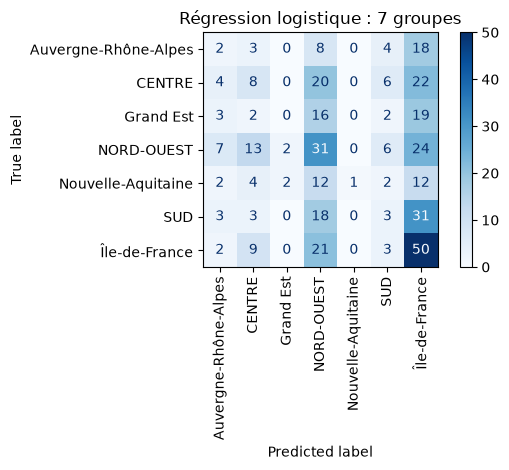

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test_g, predictions_logistique, xticks_rotation=90, cmap="Blues")
plt.title("Régression logistique : 7 groupes")
plt.tight_layout()
plt.show()

## 5. Résultats

On compare les scores. K-Means est ici évalué sur les 12 régions.

In [16]:
resultats = pd.DataFrame({
    "Modèle": ["Random Forest (12 régions)", "Random Forest (7 groupes)", "K-Means (12 régions)", "Régression logistique (7 groupes)"],
    "Accuracy": [accuracy_12, accuracy_7, accuracy_kmeans, accuracy_logistique],
    "F1 macro": [f1_12, f1_7, f1_kmeans, f1_logistique]
})
display(resultats.round(3))

,Modèle,Accuracy,F1 macro
0,Random Forest (12 régions),0.191,0.051
1,Random Forest (7 groupes),0.249,0.148
2,K-Means (12 régions),0.214,0.029
3,Régression logistique (7 groupes),0.239,0.148


# Deep Learning : réseaux de neurones

On entraîne deux réseaux : un pour les 12 régions et un pour les 7 groupes. Ils utilisent les mêmes personnes en entraînement et en test que les modèles précédents.

In [17]:
# Même découpage que les modèles classiques ; seules les étiquettes changent.
tf.keras.utils.set_random_seed(42)

def creer_reseau(nb_features, nb_classes):
    reseau = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(nb_features,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(nb_classes, activation="softmax")
    ])
    reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return reseau

def evaluer_reseau(nom, cible):
    if cible == "region":
        X_app, X_eval = X_train, X_test
        y_app_brut, y_eval_brut = y_train, y_test
    elif cible == "region_group":
        X_app, X_eval = X_train_g, X_test_g
        y_app_brut, y_eval_brut = y_train_g, y_test_g
    else:
        raise ValueError(f"Cible non prévue : {cible}")

    encodeur = LabelEncoder()
    y_app = encodeur.fit_transform(y_app_brut)
    y_eval = encodeur.transform(y_eval_brut)

    normaliseur = StandardScaler()
    X_app = normaliseur.fit_transform(X_app.astype("float32"))
    X_eval = normaliseur.transform(X_eval.astype("float32"))

    poids = compute_class_weight("balanced", classes=np.unique(y_app), y=y_app)
    poids_classes = dict(zip(np.unique(y_app), poids))

    tf.keras.utils.set_random_seed(42)
    reseau = creer_reseau(X_app.shape[1], len(encodeur.classes_))
    historique = reseau.fit(
        X_app, y_app, validation_split=0.2, epochs=100, batch_size=32,
        class_weight=poids_classes,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=10, restore_best_weights=True
        )], verbose=0
    )
    predictions_dl = reseau.predict(X_eval, verbose=0).argmax(axis=1)
    print(f"\n{nom}")
    print(classification_report(
        y_eval, predictions_dl, labels=range(len(encodeur.classes_)),
        target_names=encodeur.classes_, zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_eval, predictions_dl, display_labels=encodeur.classes_,
        xticks_rotation=90, cmap="Blues"
    )
    plt.title(nom)
    plt.tight_layout()
    plt.show()
    pd.DataFrame(historique.history)[["loss", "val_loss"]].plot(
        title=f"Perte pendant l'entraînement : {nom}"
    )
    plt.show()
    return {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_eval, predictions_dl),
        "F1 macro": f1_score(y_eval, predictions_dl, average="macro", zero_division=0)
    }

## Entraînement et évaluation des deux réseaux

On utilise la même architecture pour les deux cibles, sans répéter le code.


Deep Learning (12 régions)
                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.15      0.09      0.11        35
   Bourgogne-Franche-Comté       0.10      0.56      0.17        18
                  Bretagne       0.12      0.10      0.11        21
       Centre-Val de Loire       0.00      0.00      0.00        19
                 Grand Est       0.06      0.05      0.05        42
           Hauts-de-France       0.00      0.00      0.00        43
                 Normandie       0.05      0.16      0.07        19
        Nouvelle-Aquitaine       0.11      0.06      0.07        35
                 Occitanie       0.15      0.11      0.13        35
          Pays de la Loire       0.06      0.09      0.07        23
Provence-Alpes-Côte d'Azur       0.00      0.00      0.00        23
             Île-de-France       0.18      0.11      0.13        85

                  accuracy                           0.09       398
                 m

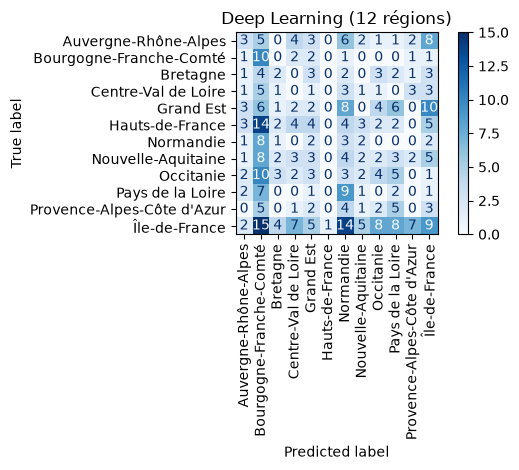

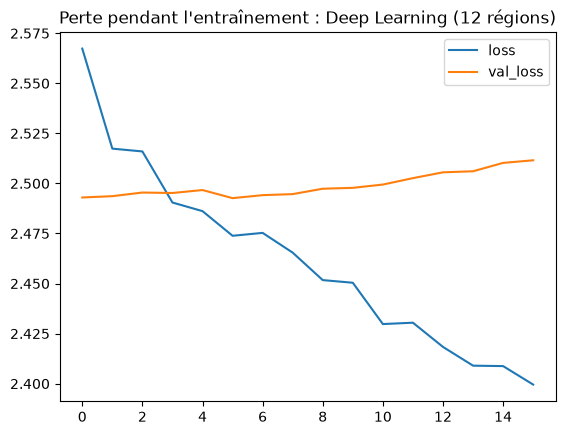


Deep Learning (premier regroupement)
                      precision    recall  f1-score   support

Auvergne-Rhône-Alpes       0.08      0.09      0.08        35
              CENTRE       0.20      0.23      0.22        60
           Grand Est       0.19      0.17      0.18        42
          NORD-OUEST       0.23      0.16      0.19        83
  Nouvelle-Aquitaine       0.12      0.14      0.13        35
                 SUD       0.17      0.21      0.19        58
       Île-de-France       0.28      0.29      0.29        85

            accuracy                           0.20       398
           macro avg       0.18      0.18      0.18       398
        weighted avg       0.20      0.20      0.20       398



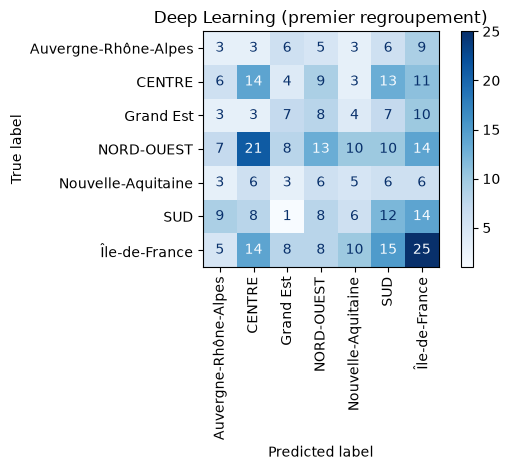

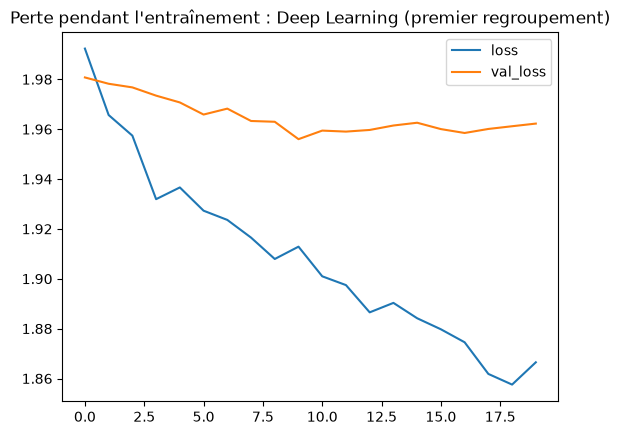

In [18]:
configurations_dl = [
    ("Deep Learning (12 régions)", "region"),
    ("Deep Learning (premier regroupement)", "region_group")
]

scores_dl = [evaluer_reseau(nom, cible) for nom, cible in configurations_dl]

## Comparaison de tous les modèles

On rassemble les résultats du Random Forest, de K-Means, de la régression logistique et des deux réseaux de neurones.

In [19]:
resultats_complets = pd.concat([resultats, pd.DataFrame(scores_dl)], ignore_index=True)
display(resultats_complets.round(3))

,Modèle,Accuracy,F1 macro
0,Random Forest (12 régions),0.191,0.051
1,Random Forest (7 groupes),0.249,0.148
2,K-Means (12 régions),0.214,0.029
3,Régression logistique (7 groupes),0.239,0.148
4,Deep Learning (12 régions),0.093,0.077
5,Deep Learning (premier regroupement),0.198,0.182


## Conclusion
Nous avons testé plusieurs modèles pour prédire la région à partir des goûts musicaux.

Les résultats restent assez faibles. Le Random Forest obtient les meilleurs scores d'accuracy, tandis que le Deep Learning n'apporte pas trop d'amélioration.

Ce qui montre que les goûts musicaux seuls ne suffisent pas à prédire facilement la région d'une personne